# CAI 4105 - Challenge 1
## Team 8: Apartment Rental Price Prediction

This notebook shows the complete machine learning workflow, from loading the data to generating `predictions.csv`.

- **Models:** Linear Regression, Decision Tree, Random Forest, and Gradient Boosting
- **Validation:** shared train/validation split, RMSE, and Grid Search with cross-validation
- **Final model:** the model with the lowest validation RMSE, retrained on all labeled training data

Preprocessing is shared through `preprocessing.py` so every model uses identical data and transformations.


In [1]:
%matplotlib inline

## Setup: imports and helper function


In [2]:
# CAI 4105 - Team 8 - Challenge 1
# Complete rental price prediction workflow

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.model_selection import GridSearchCV

from preprocessing import (
    load_splits,
    load_test,
    build_preprocessor,
    rmse,
    FEATURES,
    TARGET
)

RANDOM_STATE = 42


def make_pipeline(model):
    return Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", model)
    ])

## 1. Load shared training and validation data


In [3]:
train, val = load_splits()

X_train = train[FEATURES]
y_train = train[TARGET]
X_val = val[FEATURES]
y_val = val[TARGET]

assert len(train) > 0 and len(val) > 0
assert not y_train.isna().any()
assert not y_val.isna().any()

print("Training rows:", len(train))
print("Validation rows:", len(val))

Training rows: 5918
Validation rows: 1480


## 2. Define four required regression models


In [4]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=RANDOM_STATE
    )
}

results = []
candidates = {}


def evaluate(name, pipeline):
    train_predictions = pipeline.predict(X_train)
    val_predictions = pipeline.predict(X_val)

    train_score = rmse(y_train, train_predictions)
    val_score = rmse(y_val, val_predictions)

    results.append({
        "Model": name,
        "Training RMSE": train_score,
        "Validation RMSE": val_score,
        "RMSE Gap": val_score - train_score
    })

    candidates[name] = pipeline

    print(
        name,
        "| Training RMSE:", round(train_score, 2),
        "| Validation RMSE:", round(val_score, 2)
    )

## 3. Train and evaluate baseline models


In [5]:
print("\nBASELINE MODEL RESULTS")

for name, model in models.items():
    pipeline = make_pipeline(model)
    pipeline.fit(X_train, y_train)
    evaluate(name, pipeline)


BASELINE MODEL RESULTS
Linear Regression | Training RMSE: 515.14 | Validation RMSE: 550.04
Decision Tree | Training RMSE: 39.35 | Validation RMSE: 559.31


Random Forest | Training RMSE: 159.57 | Validation RMSE: 453.32


Gradient Boosting | Training RMSE: 405.21 | Validation RMSE: 487.96


## 4. Grid Search: Random Forest


In [6]:
print("\nTUNING RANDOM FOREST")

rf_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [1, 3]
}

rf_search = GridSearchCV(
    estimator=make_pipeline(
        RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1
        )
    ),
    param_grid=rf_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best RF parameters:", rf_search.best_params_)
print("RF CV RMSE:", round(-rf_search.best_score_, 2))

evaluate("Tuned Random Forest", rf_search.best_estimator_)


TUNING RANDOM FOREST


Best RF parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
RF CV RMSE: 432.6
Tuned Random Forest | Training RMSE: 268.7 | Validation RMSE: 453.49


## 5. Grid Search: Gradient Boosting


In [7]:
print("\nTUNING GRADIENT BOOSTING")

gb_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [1, 5]
}

gb_search = GridSearchCV(
    estimator=make_pipeline(
        GradientBoostingRegressor(
            random_state=RANDOM_STATE
        )
    ),
    param_grid=gb_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1,
    refit=True
)

gb_search.fit(X_train, y_train)

print("Best GB parameters:", gb_search.best_params_)
print("GB CV RMSE:", round(-gb_search.best_score_, 2))

evaluate(
    "Tuned Gradient Boosting",
    gb_search.best_estimator_
)


TUNING GRADIENT BOOSTING


Best GB parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
GB CV RMSE: 434.24
Tuned Gradient Boosting | Training RMSE: 368.24 | Validation RMSE: 455.61


## 6. Compare all models


In [8]:
comparison = pd.DataFrame(results)
comparison = comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)

comparison.to_csv("model_comparison.csv", index=False)

print("\nCOMPLETE MODEL COMPARISON")
print(comparison.round(2).to_string(index=False))

print("\nOVERFITTING ANALYSIS")
for _, row in comparison.iterrows():
    print(
        row["Model"],
        "| Validation - Training RMSE:",
        round(row["RMSE Gap"], 2)
    )

print(
    "\nA large positive gap may indicate overfitting."
)


COMPLETE MODEL COMPARISON
                  Model  Training RMSE  Validation RMSE  RMSE Gap
          Random Forest         159.57           453.32    293.74
    Tuned Random Forest         268.70           453.49    184.79
Tuned Gradient Boosting         368.24           455.61     87.37
      Gradient Boosting         405.21           487.96     82.75
      Linear Regression         515.14           550.04     34.90
          Decision Tree          39.35           559.31    519.96

OVERFITTING ANALYSIS
Random Forest | Validation - Training RMSE: 293.74
Tuned Random Forest | Validation - Training RMSE: 184.79
Tuned Gradient Boosting | Validation - Training RMSE: 87.37
Gradient Boosting | Validation - Training RMSE: 82.75
Linear Regression | Validation - Training RMSE: 34.9
Decision Tree | Validation - Training RMSE: 519.96

A large positive gap may indicate overfitting.


## 7. Select best model by validation RMSE


In [9]:
best_name = comparison.iloc[0]["Model"]
best_pipeline = candidates[best_name]

print("\nSELECTED FINAL MODEL:", best_name)
print(
    "Validation RMSE:",
    round(comparison.iloc[0]["Validation RMSE"], 2)
)

print(
    "Selected because it achieved the lowest "
    "validation RMSE among evaluated candidates."
)


SELECTED FINAL MODEL: Random Forest
Validation RMSE: 453.32
Selected because it achieved the lowest validation RMSE among evaluated candidates.


## 8. Plot actual vs predicted prices


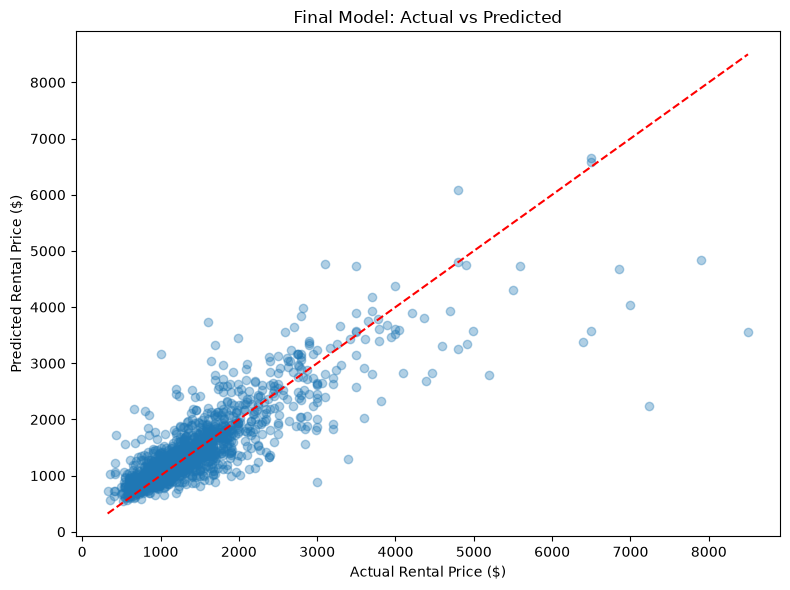

In [10]:
val_predictions = best_pipeline.predict(X_val)

plt.figure(figsize=(8, 6))
plt.scatter(y_val, val_predictions, alpha=0.35)

limits = [
    min(y_val.min(), val_predictions.min()),
    max(y_val.max(), val_predictions.max())
]

plt.plot(limits, limits, "r--")
plt.xlabel("Actual Rental Price ($)")
plt.ylabel("Predicted Rental Price ($)")
plt.title("Final Model: Actual vs Predicted")
plt.tight_layout()
plt.savefig("final_model_plot.png", dpi=150)
plt.show()

## 9. Train final model on all available training data


In [11]:
full_train_path = "data/challenge1_train.csv"

if os.path.exists(full_train_path):
    full_train = pd.read_csv(full_train_path)
else:
    # Use the team's shared training and validation
    # partitions if the original CSV is unavailable.
    full_train = pd.concat(
        [train, val],
        ignore_index=True
    )

if "ID" in full_train.columns:
    assert full_train["ID"].is_unique

X_full = full_train[FEATURES]
y_full = full_train[TARGET]

assert not y_full.isna().any()

print("\nRetraining selected model on", len(full_train), "rows")

# Refit selected pipeline using all labeled training data.
best_pipeline.fit(X_full, y_full)


Retraining selected model on 7398 rows


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['bathrooms','bedrooms','square_feet',...,'longitude','has_photo','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

## 10. Generate competition predictions


In [12]:
test = load_test()

assert len(test) == 2467, (
    "Expected 2467 test observations."
)
assert "ID" in test.columns
assert test["ID"].is_unique
assert TARGET not in test.columns

X_test = test[FEATURES]

predicted_prices = best_pipeline.predict(X_test)

assert len(predicted_prices) == len(test)
assert np.isfinite(predicted_prices).all()

predictions = pd.DataFrame({
    "ID": test["ID"].values,
    "price": predicted_prices
})

assert predictions["ID"].equals(
    test["ID"].reset_index(drop=True)
)

predictions.to_csv("predictions.csv", index=False)

print("\nPREDICTIONS CREATED")
print(predictions.head())
print("Prediction rows:", len(predictions))


PREDICTIONS CREATED
   ID        price
0   1  1376.710000
1   4  1743.000000
2   9  1029.850000
3  11   662.320000
4  13   616.945835
Prediction rows: 2467


## 11. Final report


In [13]:
print("\n========== FINAL REPORT ==========")
print("Selected model:", best_name)
print(
    "Validation RMSE:",
    round(comparison.iloc[0]["Validation RMSE"], 2)
)
print("Full training rows:", len(full_train))
print("Test predictions:", len(predictions))
print("Files generated:")
print("- model_comparison.csv")
print("- predictions.csv")
print("- final_model_plot.png")
print("\nChallenge modeling workflow completed.")


========== FINAL REPORT ==========
Selected model: Random Forest
Validation RMSE: 453.32
Full training rows: 7398
Test predictions: 2467
Files generated:
- model_comparison.csv
- predictions.csv
- final_model_plot.png

Challenge modeling workflow completed.
